# Problem set 6: The Solow model

**What you will practice**

* Extending a model you already know: **technology growth** and **population growth**.
* Writing a **class** with a **simulator method**, structured like the one from lecture 9.
* **Testing** new code with `assert` against cases you can already solve.
* Simulating a model where **several parameters are stochastic**.
* Making figures with `fig` and `ax` that are easy to read.

**Answers.** After each question there is a cell like `import A1` + `A1.run()`. Write your own code first, then run the answer cell and compare.

**Table of contents**<a id='toc0_'></a>    
- 1. [The steady state](#toc1_)    
- 2. [The steady-state diagram](#toc2_)    
- 3. [A class with a simulator](#toc3_)    
- 4. [A permanent fall in population growth](#toc4_)    
- 5. [Stochastic saving, technology and population](#toc5_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
%load_ext autoreload
%autoreload 2

from types import SimpleNamespace
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'-'})
plt.rcParams.update({'font.size':14})

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

from solow import SolowModel # the model from lecture 9

In the lecture the number of workers and the level of technology were constant. Now we let both **grow at constant rates**,

$$ A_{t+1} = (1+g)A_t, \qquad L_{t+1} = (1+n)L_t $$

where $A_t$ is technology (how productive a worker is) and $L_t$ is the number of workers. Production now uses both capital and *effective* labour $A_tL_t$,

$$ Y_t = K_t^{\alpha}(A_tL_t)^{1-\alpha}, \qquad K_{t+1} = sY_t + (1-\delta)K_t $$

Because $A_tL_t$ grows, $K_t$ and $Y_t$ keep growing too, and there is no steady state in *levels*. The trick is to measure everything **per effective worker**,

$$ \tilde{k}_t \equiv \frac{K_t}{A_tL_t}, \qquad \tilde{y}_t \equiv \frac{Y_t}{A_tL_t} = \tilde{k}_t^{\alpha} $$

Dividing the capital accumulation equation by $A_{t+1}L_{t+1} = (1+g)(1+n)A_tL_t$ gives the **law of motion**

$$ \tilde{k}_{t+1} = \frac{s f(\tilde{k}_t) + (1-\delta)\tilde{k}_t}{(1+g)(1+n)} $$

and setting $\tilde{k}_{t+1} = \tilde{k}_t = \tilde{k}^{\ast}$ gives the **steady state**

$$ s f(\tilde{k}^{\ast}) = \underbrace{\big[(1+g)(1+n)-(1-\delta)\big]}_{\text{break-even investment}}\tilde{k}^{\ast}
\qquad \Rightarrow \qquad
\tilde{k}^{\ast} = \left(\frac{s}{(1+g)(1+n)-(1-\delta)}\right)^{\frac{1}{1-\alpha}} $$

Investment now has to do more than replace worn-down capital: it also has to equip the new workers and keep up with better technology. For $g = n = 0$ everything collapses back to the model from the lecture.

**The model from the lecture** is in the file [solow.py](solow.py) and was imported above. Use it as a **template** for your own class - and as a **test** of your new formulas.

In [2]:
model_lecture = SolowModel()
print(model_lecture)

Solow model with:
  alpha = 0.33 (capital share)
  s     = 0.20 (savings rate)
  delta = 0.30 (depreciation rate)
  k0    = 0.10 (initial capital per worker)
  T     = 50 (number of periods)


**Parameters used throughout the problem set:**

| parameter | value | meaning |
| --- | --- | --- |
| $\alpha$ | 1/3 | capital share |
| $s$ | 0.20 | savings rate |
| $\delta$ | 0.30 | depreciation rate |
| $g$ | 0.03 | growth rate of technology |
| $n$ | 0.04 | growth rate of the population |

## 1. <a id='toc1_'></a>[The steady state](#toc0_)

**Question:** Write a function `k_star(alpha,s,delta,g,n)` returning the steady-state capital **per effective worker**, and print it for the parameters above.

**Then test it:** with $g = n = 0$ your function must give exactly the same as `SolowModel().steady_state()` from the lecture. Check it with an `assert`, as in section 4.3 of the lecture.

**Hints:**

* The break-even term is `(1+g)*(1+n)-(1-delta)`.
* `SolowModel(alpha=...,s=...,delta=...).steady_state()` returns a tuple `(k,y,c)`, so take element `[0]`.
* `assert np.isclose(a,b), 'a and b are not the same'`

In [3]:
# write your own code here

In [4]:
import A1
A1.run()

parameters: alpha = 0.33, s = 0.20, delta = 0.30, g = 0.03, n = 0.04
steady state: k* = 0.3955 (per effective worker)

without growth (g=n=0): k* = 0.5443
the model from lecture 9: k* = 0.5443
test passed

growth in A and L lowers k* by 27.3 percent


## 2. <a id='toc2_'></a>[The steady-state diagram](#toc0_)

**Question:** Make **one figure** with

1. investment per effective worker, $s f(\tilde{k})$,
2. the break-even line **without** growth, $\delta \tilde{k}$,
3. the break-even line **with** growth, $[(1+g)(1+n)-(1-\delta)]\tilde{k}$,

and mark the two steady states. Explain in one sentence why growth in $A$ and $L$ moves the steady state the way it does.

**Hints:**

* Use a grid `k_grid = np.linspace(0,1,500)` and `fig, ax` as in the lecture.
* Mark a steady state with `ax.plot(k,s*k**alpha,'o')` and `ax.axvline(k,ls=':')`.
* Remember a title, axis labels and a legend.

In [5]:
# write your own code here

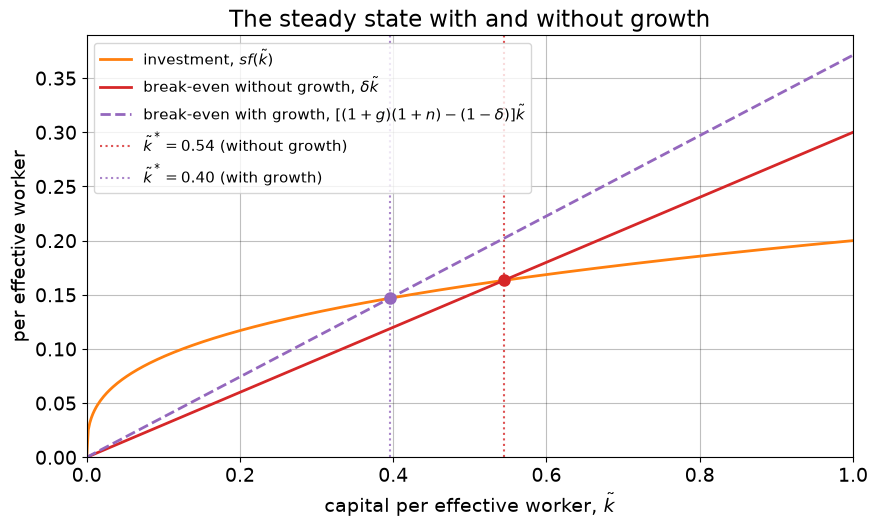

k* without growth: 0.5443
k* with growth:    0.3955

growth in A and L works exactly like a higher depreciation rate:
the capital stock has to be spread out over more and more effective workers.


In [6]:
import A2
A2.run()

## 3. <a id='toc3_'></a>[A class with a simulator](#toc0_)

**Question:** Write a class `SolowModelGrowth` structured exactly like `SolowModel` in [solow.py](solow.py), but with $g$ and $n$ - and with a `simulate` method that keeps track of the **levels** $K_t$, $A_t$, $L_t$, $Y_t$ and $C_t$:

$$ Y_t = K_t^{\alpha}(A_tL_t)^{1-\alpha}, \quad C_t = (1-s_t)Y_t $$
$$ K_{t+1} = s_tY_t + (1-\delta)K_t, \quad A_{t+1} = (1+g_t)A_t, \quad L_{t+1} = (1+n_t)L_t $$

Afterwards it should store both

* **per effective worker:** $\tilde{k}_t = K_t/(A_tL_t)$, $\tilde{y}_t = Y_t/(A_tL_t)$, $\tilde{c}_t = C_t/(A_tL_t)$
* **per worker:** $K_t/L_t$, $Y_t/L_t$, $C_t/L_t$

in `self.sim`. Let `s`, `g` and `n` be either a **number** (constant) or an **array** with one value per period - you will need that in question 6.

**Then test it** with `assert`, as in section 4.3 of the lecture. Good tests here are:

1. an economy that **starts** in the steady state must **stay** there,
2. with $g = n = 0$ your class must reproduce the model from the lecture **period by period**,
3. the population must grow at exactly the rate $n$.

**Then use it:** simulate from a low starting point and make a figure with two panels:

1. capital per effective worker $\tilde{k}_t$, with a line at the steady state $\tilde{k}^{\ast}$,
2. the **growth rate** of output per worker, `sim.y_pw[1:]/sim.y_pw[:-1]-1`, with a line at $g$.

What is the growth rate of output per worker in the long run?

**Hints:**

* Only the levels need a loop. All the per-worker variables can be computed *after* the loop with array division, e.g. `self.sim.k = K/(A*L)`.
* Copy the trick from the lecture for handling a number or an array:
  `np.full(T,x) if np.ndim(x) == 0 else np.asarray(x,dtype=float)`.

Use the skeleton below as a starting point.

In [7]:
class SolowModelGrowth:
    """ the Solow model with technology growth and population growth """

    def __init__(self,**kwargs):
        """ set the default parameters, then overwrite with any keyword arguments """

        # a. parameters
        self.alpha = 1/3 # capital share in production
        self.s = 0.20 # savings rate
        self.delta = 0.30 # depreciation rate
        self.g = 0.03 # growth rate of technology
        self.n = 0.04 # growth rate of the population

        # b. simulation settings
        self.K0 = 0.05 # initial capital
        self.A0 = 1.00 # initial technology
        self.L0 = 1.00 # initial population
        self.T = 100 # number of periods

        # c. overwrite with keyword arguments
        for key,value in kwargs.items():
            setattr(self,key,value)

        # d. empty container for simulation results
        self.sim = SimpleNamespace()

    def f(self,k):
        """ output per effective worker, y = f(k) = k**alpha """

        return k**self.alpha

    def steady_state(self):
        """ analytical steady state per effective worker, returns (k,y,c) """

        # TODO: use your formula from question 2

        return None,None,None

    def simulate(self,s=None,g=None,n=None):
        """ simulate the model forward in time, results are stored in self.sim """

        # TODO: allocate arrays, loop forward in time, store the results

        return self.sim

In [8]:
# write your own code here

all tests passed

Solow model with growth:
  alpha = 0.33 (capital share)
  s     = 0.20 (savings rate)
  delta = 0.30 (depreciation rate)
  g     = 0.03 (growth rate of technology)
  n     = 0.04 (growth rate of the population)
  T     = 60 (number of periods)

steady state (per effective worker): k* = 0.3955, y* = 0.7340
last period of the simulation:       k  = 0.3955, y  = 0.7340

growth in output per worker: first period = 0.3040, last period = 0.0300
the growth rate of technology is g = 0.0300


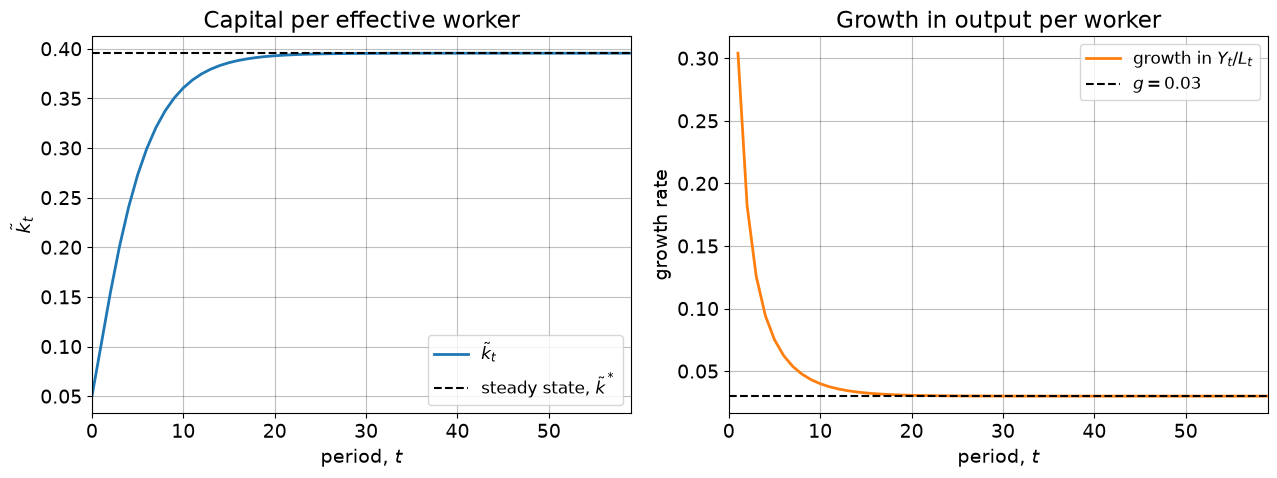


in the steady state output per worker grows at the rate of technology, g:
only technology makes us richer in the long run.


In [9]:
import A3
A3.run()

## 4. <a id='toc4_'></a>[A permanent fall in population growth](#toc0_)

Population growth is falling in most rich countries. What does that do to the economy?

**Question:** Let the economy **start in its steady state** and let population growth fall permanently from $n = 0.04$ to $n = 0.02$ in period $t_{\text{switch}} = 30$. Compare with a baseline where $n$ stays at $0.04$.

Make a figure with two panels:

1. capital per effective worker in the two scenarios, with lines at the old and the new steady state,
2. the growth rate of output per worker in the two scenarios, with a line at $g$.

Is the effect on growth **permanent** or **temporary**? What about the effect on the *level* of output per worker?

**Hints:**

* Build the path with `n_path = np.full(T,0.04)` and `n_path[t_switch:] = 0.02`, then call `simulate(n=n_path)`.
* To start in the steady state, set `K0` such that $K_0/(A_0L_0) = \tilde{k}^{\ast}$.
* Mark the switch with `ax.axvline(t_switch,lw=6,color='black',alpha=0.15,zorder=0)`.

In [10]:
# write your own code here

population growth: 0.040 -> 0.020 in period 30
steady state (per effective worker): k* = 0.3955 -> 0.4309
output per worker in the last period is 2.9 percent higher than in the baseline


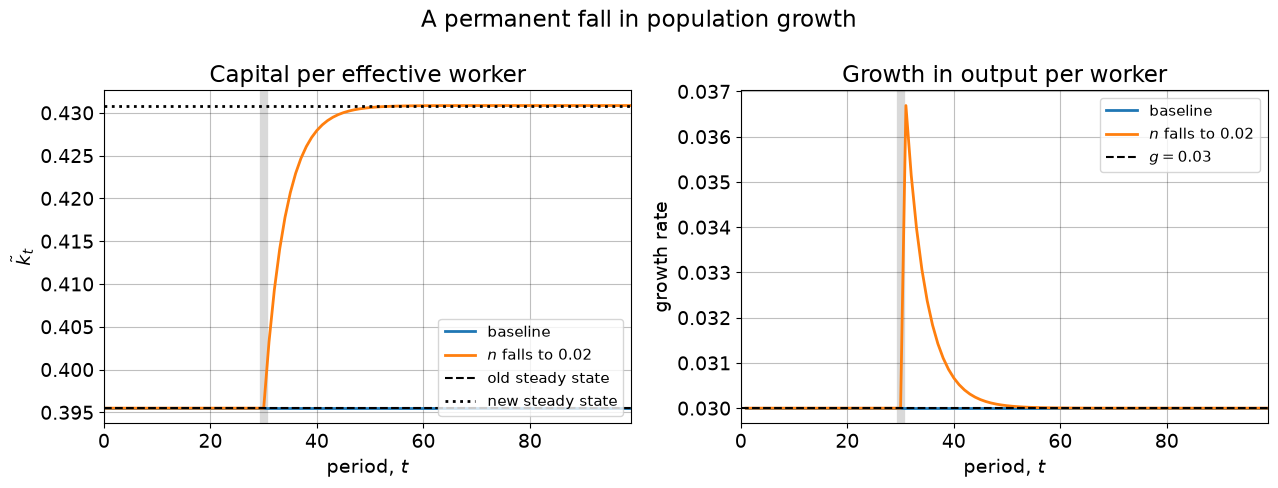


the fall in n gives a temporary boost to growth and a permanently higher
level of output per worker - but in the long run growth is back at g.


In [11]:
import A4
A4.run()

## 5. <a id='toc5_'></a>[Stochastic saving, technology and population](#toc0_)

In the lecture only the savings rate was stochastic. Now **all three** of $s_t$, $g_t$ and $n_t$ fluctuate, each as an AR(1) process,

$$ x_t = (1-\rho)\bar{x} + \rho x_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0,\sigma^2) $$

For the savings rate, run the process **in logs** (as in the lecture) so that $s_t$ is always positive. For $g_t$ and $n_t$ the level is fine - they are allowed to be negative.

**Question:**

1. Write a function `draw_ar1(rng,T,mean,rho,sigma)` returning one AR(1) path, and a function that uses it to draw the three paths $s_t$, $g_t$ and $n_t$.
2. Simulate `N = 500` economies, each with its own draws, starting from the deterministic steady state. Store $\tilde{k}_t$ for all of them in an array with shape `(N,T)`.
3. For each economy compute the **average growth rate** of output per worker over the whole simulation, `(y_pw[-1]/y_pw[0])**(1/(T-1))-1`.
4. Make a figure with two panels: a **fan chart** of $\tilde{k}_t$ (median and the 10th-90th percentile band across economies) and a **histogram** of the average growth rates. Mark the deterministic values in both panels.

Are the economies more spread out in the *level* of capital or in their *long-run growth rate*? Why?

**Hints:**

* Suggested sizes of the shocks: $\rho = 0.90$, $\sigma_s = 0.07$, $\sigma_g = \sigma_n = 0.005$.
* Use one generator `rng = np.random.default_rng(2026)` for all the draws.
* Percentiles across economies: `np.percentile(k_all,10,axis=0)`.
* A band is drawn with `ax.fill_between(np.arange(T),k_low,k_high,alpha=0.30)`.
* Remember to **copy** the result out of `sim` inside the loop - the next call overwrites it.

In [12]:
# write your own code here

capital per effective worker in the last period:
  mean = 0.4022, std = 0.0824 (deterministic: 0.3955)

average growth in output per worker:
  mean = 0.0297, std = 0.0045 (deterministic: 0.0300)
  10th-90th percentile: 0.0239 to 0.0355


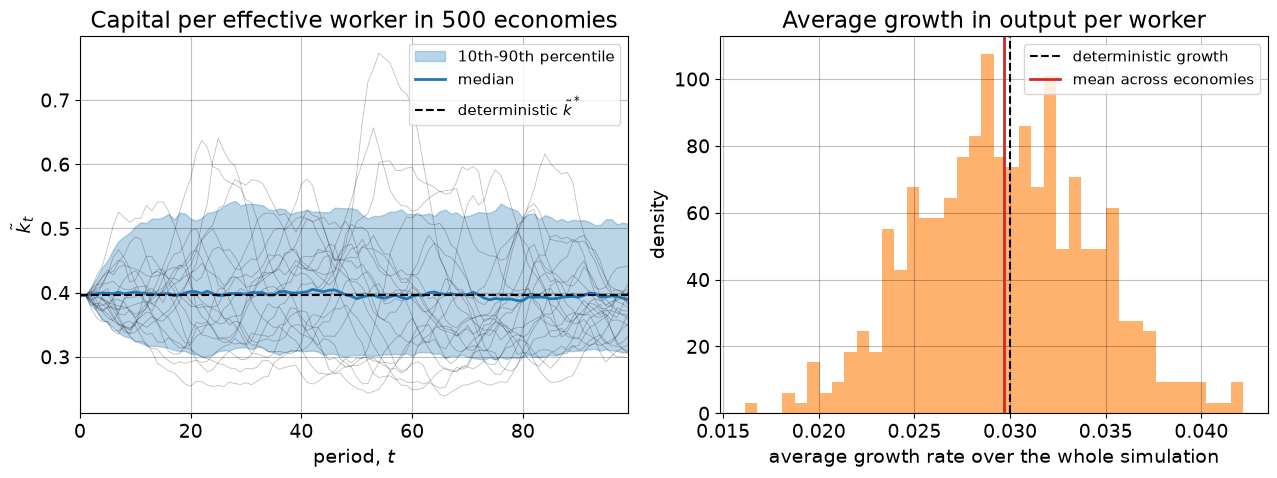


the shocks average out over time, so the growth rates are much less spread out
than the shocks themselves - but the level of capital keeps moving around.


In [13]:
import A5
A5.run()